# Backward Oversmoothing: why is it hard to train deep Graph Neural Networks?

**Artículo de referencia:** Keriven (2026), [*Backward Oversmoothing: why is it hard to train deep Graph Neural Networks?*](https://proceedings.mlr.press/v306/keriven26a.html), ICML 2026.

**Intervención:** PairNorm, propuesto por Zhao y Akoglu (2020), [*PairNorm: Tackling Oversmoothing in GNNs*](https://openreview.net/forum?id=rkecl1rtwB).

## Pregunta de investigación

¿La incorporación de PairNorm en las capas ocultas de una GNN profunda reduce el *backward oversmoothing* y permite alcanzar una menor pérdida de entrenamiento que la misma red sin normalización?

## Hipótesis

Incorporar PairNorm en las capas ocultas de una GNN profunda reducirá el *backward oversmoothing* en las capas intermedias y permitirá alcanzar una menor pérdida de entrenamiento respecto de la misma GNN sin normalización.

- **H1a:** comparar $E_\pi(B)$ (ecuación 9 del artículo) en las capas intermedias y registrar también la norma de la señal backward.
- **H1b:** comparar la pérdida de entrenamiento después de 1.000 épocas.

**Diseño:** Cora; GNN de 100 capas; configuraciones C1, C2 y C3; cuatro semillas (0, 1, 2 y 3) y dos condiciones por semilla (sin PairNorm y con PairNorm). **Total: 24 entrenamientos de modelos**.


## 1. Datos, parámetros y procedencia

| Elemento | Valor utilizado | Procedencia y motivo |
|---|---|---|
| Dataset | Cora: 2.708 publicaciones, 1.433 indicadores binarios de palabras y siete clases | Definición del dataset Cora/Planetoid. Cada nodo representa una publicación y las conexiones representan citas. |
| Grafo utilizado | No dirigido; se conserva la componente conexa de mayor tamaño | Procesamiento del apéndice B del artículo; al aplicarlo, permanecen 2.485 publicaciones. |
| Propagación | $P=D^{-1}A$ | Ecuación (1) y sección 2 del artículo. |
| Arquitectura | 100 capas, Leaky ReLU oculta y salida lineal | Configuración y experimentos del artículo. |
| Objetivo | Etiquetas de clase como valores de regresión, pérdida $\mathcal L=\frac1{2n}\|H^{(L)}-Y\|_F^2$ | Ecuaciones (4) y (5) y apéndice B del artículo. |
| Inicialización | $W=I+0.001N$, con entradas normales estándar independientes en $N$ | Forma $I+\varepsilon N$ utilizada en el artículo; se fijó $\varepsilon=0.001$ como perturbación pequeña. Se usa identidad rectangular cuando corresponde. |
| Dimensiones ocultas | 32 (C1 y C2), 64 (C3) | Elección del protocolo para observar el comportamiento con dos tamaños de representación. |
| Tasas de aprendizaje | 0.0001, 0.0006 y 0.0003 | Valores presentados en la figura 5 del artículo, asignados a C1, C2 y C3. |
| Optimizador | Adam, parámetros predeterminados de PyTorch | Elección de entrenamiento aplicada por igual a ambas condiciones. |
| PairNorm | `scale=1`, `scale_individually=False`, `eps=1e-5` | Implementación estándar de PyTorch Geometric basada en Zhao y Akoglu (2020). |
| Cuatro semillas | 0, 1, 2 y 3 para las tres configuraciones | Elección del protocolo para realizar comparaciones pareadas con un costo computacional manejable. |
| Duración | 1.000 épocas | Horizonte de entrenamiento empleado en los experimentos mostrados en el artículo. |
| Medición por capa | Épocas 0, 100, 500 y 1.000; capas centrales 34–67 | Elecciones del protocolo para observar la evolución y resumir la zona central de una red de 100 capas. |

**Comparación controlada:** cada pareja de modelos emplea el mismo grafo, semilla, arquitectura, optimizador y pesos iniciales; la condición con PairNorm incorpora únicamente esa operación en las capas ocultas. No se añaden lazos propios ni otra transformación de características.


## 2. Instalación para Google Colab

Se instala **PyTorch Geometric 2.8.1**, versión publicada compatible con Python 3.13, junto con las bibliotecas de análisis. Esta versión se fija para evitar que se instale una versión más antigua permitida por un intervalo amplio.

**Importante:** después de ejecutar la siguiente celda de instalación, usa **Entorno de ejecución → Reiniciar sesión** y vuelve a ejecutar el notebook desde el principio. Esto evita reutilizar una importación incompleta de `torch_geometric` en la misma sesión. La instalación no modifica las ecuaciones, los datos ni las configuraciones C1, C2 y C3.


In [10]:
%pip install -q --upgrade --no-cache-dir "torch-geometric==2.8.1" pandas scipy matplotlib tqdm

In [11]:
import sys, platform, json, math, os, random, time, gc, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from tqdm.auto import tqdm
import torch
from torch import nn
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import PairNorm
from torch_geometric.utils import to_undirected, subgraph
import torch_geometric

print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| PyG:', torch_geometric.__version__)
print('NumPy:', np.__version__, '| SciPy:', scipy.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE)

Python: 3.13.18 | PyTorch: 2.14.1+cpu | PyG: 2.8.1
NumPy: 2.4.6 | SciPy: 1.18.1
Dispositivo: cpu


## 3. Configuraciones y almacenamiento

Se entrenan dos condiciones (`referencia` y `pairnorm`) con las **mismas cuatro semillas** en cada configuración:

| Configuración | Dimensión oculta | Tasa de aprendizaje | Semillas |
|---|---:|---:|---|
| C1 | 32 | 0.0001 | 0, 1, 2, 3 |
| C2 | 32 | 0.0006 | 0, 1, 2, 3 |
| C3 | 64 | 0.0003 | 0, 1, 2, 3 |

La comparación C1–C2 cambia solo la tasa de aprendizaje. C3 utiliza una dimensión oculta y una tasa diferentes, por lo que no se atribuye la diferencia observada exclusivamente al tamaño de la capa.

El notebook guarda un checkpoint por entrenamiento y las mediciones en CSV. Cuando hay un checkpoint correspondiente a la configuración y semilla solicitadas, se comprueba y se utiliza; en caso contrario, se ejecuta el entrenamiento.


In [12]:
# Tres configuraciones, cuatro semillas compartidas y dos condiciones por semilla.
CONFIGS = [
    {'config_id':'C1', 'hidden_dim':32, 'lr':1e-4, 'init_eps':0.001},
    {'config_id':'C2', 'hidden_dim':32, 'lr':6e-4, 'init_eps':0.001},
    {'config_id':'C3', 'hidden_dim':64, 'lr':3e-4, 'init_eps':0.001},
]
SEEDS = [0,1,2,3]
SEEDS_BY_CONFIG = {cfg['config_id']: list(SEEDS) for cfg in CONFIGS}
PRIMARY_SEEDS = list(SEEDS)
PRIMARY_CONFIGS = [cfg['config_id'] for cfg in CONFIGS]
CONDITIONS = ['referencia','pairnorm']
LAYERS = 100
EPOCHS = 1000
CHECKPOINT_EVERY = 100
PROFILE_EPOCHS = [0,100,500,1000]
PAIRNORM_CONFIG = {'scale':1.0, 'scale_individually':False, 'eps':1e-5}
NEGATIVE_SLOPE = 0.01
ADAM_KWARGS = {'betas':(0.9,0.999), 'eps':1e-8, 'weight_decay':0.0}

# Guardar los resultados y checkpoints en Google Drive.
from google.colab import drive; drive.mount('/content/drive')
OUTPUT_DIR = Path('/content/drive/MyDrive/Keriven_PairNorm')
#OUTPUT_DIR = Path('Keriven_PairNorm').resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLAN = [(cfg,seed,condition)
        for cfg in CONFIGS for seed in SEEDS for condition in CONDITIONS]
PRIMARY_KEYS = {(cid,s,condition) for cid in PRIMARY_CONFIGS
                for s in SEEDS for condition in CONDITIONS}
assert len(PLAN)==24 and len(PRIMARY_KEYS)==24
assert all(SEEDS_BY_CONFIG[cid]==SEEDS for cid in PRIMARY_CONFIGS)
assert len({(cfg['config_id'],s,condition) for cfg,s,condition in PLAN})==24
print(pd.DataFrame(CONFIGS).to_string(index=False))
print('Semillas idénticas en C1, C2, C3:', SEEDS)
print('Entrenamientos planificados:',len(PLAN),'= 3 configuraciones × 4 semillas × 2 condiciones')
print('Carpeta de resultados/checkpoints:', OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
config_id  hidden_dim     lr  init_eps
       C1          32 0.0001     0.001
       C2          32 0.0006     0.001
       C3          64 0.0003     0.001
Semillas idénticas en C1, C2, C3: [0, 1, 2, 3]
Entrenamientos planificados: 24 = 3 configuraciones × 4 semillas × 2 condiciones
Carpeta de resultados/checkpoints: /content/drive/MyDrive/Keriven_PairNorm


## 4. Preparación de Cora y matriz de propagación

Se carga Cora con `Planetoid`, se convierten las relaciones de citación en conexiones no dirigidas y se conserva la **componente conexa de mayor tamaño**, siguiendo el procesamiento descrito en el apéndice B del artículo. Una componente conexa es un grupo de nodos entre los que existe un camino en el grafo.

Cada nodo es una publicación científica, con 1.433 indicadores binarios de palabras y una etiqueta entre siete categorías. Cora contiene 2.708 publicaciones antes del procesamiento; el número de nodos utilizado se obtiene en la siguiente celda.

La propagación de la GNN se calcula con $P=D^{-1}A$ (artículo, sección 2): $A$ es la matriz de conexiones y $D$ la diagonal con el número de vecinos de cada nodo. Para facilitar el cálculo, $P$ se almacena como matriz dispersa. No se agregan lazos propios ni normalización adicional de características.

### Carga de archivos de Cora

La siguiente celda obtiene los archivos públicos de Cora utilizados por `Planetoid`. Los guarda en la carpeta `data/Planetoid/Cora/raw`; si ya existen, evita descargarlos otra vez. Las rutas alternativas y los reintentos solo sirven para completar la descarga, sin modificar los datos.

In [13]:
# Descarga robusta de los ficheros originales de Cora (Planetoid).
# Solo actúa sobre el transporte; el dataset y el preprocesamiento son idénticos.
import requests
from urllib.parse import quote

CORA_ROOT = Path('data/Planetoid')
CORA_RAW = CORA_ROOT / 'Cora' / 'raw'
CORA_FILES = [f'ind.cora.{part}' for part in (
    'x', 'tx', 'allx', 'y', 'ty', 'ally', 'graph', 'test.index'
)]
CORA_ORIGINS = [
    'https://raw.githubusercontent.com/kimiyoung/planetoid/master/data',
    'https://cdn.jsdelivr.net/gh/kimiyoung/planetoid@master/data',
]

def _es_archivo_de_datos(path):
    if not path.is_file() or path.stat().st_size < 20:
        return False
    # Evita aceptar HTML de un proxy/CDN como si fueran los datos de Planetoid.
    with open(path, 'rb') as fh:
        head = fh.read(256).lstrip().lower()
    return not (head.startswith(b'<!doctype') or head.startswith(b'<html')
                or head.startswith(b'<?xml'))

def descargar_cora_si_falta(raw_dir=CORA_RAW, intentos_por_origen=3):
    raw_dir = Path(raw_dir)
    raw_dir.mkdir(parents=True, exist_ok=True)
    descargados = []
    for filename in CORA_FILES:
        target = raw_dir / filename
        if _es_archivo_de_datos(target):
            continue
        errors = []
        for origin in CORA_ORIGINS:
            if _es_archivo_de_datos(target):
                break
            for intento in range(intentos_por_origen):
                tmp = target.with_suffix(target.suffix + '.download')
                try:
                    # requests verifica el código HTTP; descargar en bloques evita
                    # almacenar la respuesta entera en memoria.
                    with requests.get(f'{origin}/{quote(filename)}',
                                      stream=True, timeout=(10, 45)) as response:
                        response.raise_for_status()
                        with open(tmp, 'wb') as fd:
                            for block in response.iter_content(chunk_size=65536):
                                if block:
                                    fd.write(block)
                    if not _es_archivo_de_datos(tmp):
                        raise ValueError('El servidor no devolvió un fichero de datos válido')
                    os.replace(tmp, target)
                    descargados.append(filename)
                    print('Descargado:', filename, '| fuente:', origin)
                    break
                except (requests.RequestException, OSError, ValueError) as ex:
                    errors.append(f'{origin} intento {intento+1}: {ex}')
                    tmp.unlink(missing_ok=True)
                    # Pausa corta solo ante errores de red; no modifica el entrenamiento.
                    time.sleep(min(2 * (intento + 1), 6))
        if not _es_archivo_de_datos(target):
            raise RuntimeError(
                f'No fue posible descargar {filename}. Revisa conectividad y vuelve a ejecutar. '
                + ' | '.join(errors[-4:])
            )
    print('Cora listo:', len(CORA_FILES), 'ficheros originales presentes en', raw_dir)
    return raw_dir

descargar_cora_si_falta()


Cora listo: 8 ficheros originales presentes en data/Planetoid/Cora/raw


PosixPath('data/Planetoid/Cora/raw')

In [14]:
def cargar_cora_y_propagacion(root=CORA_ROOT):
    dataset = Planetoid(root=root, name='Cora', transform=None)
    data = dataset[0]
    n0 = int(data.num_nodes)
    edges = to_undirected(data.edge_index, num_nodes=n0).cpu()
    scipy_A = sp.coo_matrix((np.ones(edges.shape[1],dtype=np.float64),
                             (edges[0].numpy(),edges[1].numpy())), shape=(n0,n0)).tocsr()
    scipy_A.data[:] = 1.0
    n_comp, component = connected_components(scipy_A, directed=False)
    comp_sizes = np.bincount(component)
    kept = np.flatnonzero(component == np.argmax(comp_sizes))
    kept_t = torch.tensor(kept, dtype=torch.long)
    edges, _ = subgraph(kept_t, edges, relabel_nodes=True, num_nodes=n0)
    n = len(kept)

    # Binaria; algunos cargadores contienen duplicados en edge_index.
    A = sp.coo_matrix((np.ones(edges.shape[1],dtype=np.float64),
                        (edges[0].numpy(),edges[1].numpy())), shape=(n,n)).tocsr()
    A.data[:] = 1.0
    degree = np.asarray(A.sum(axis=1)).reshape(-1)
    assert np.all(degree > 0), 'Hay un nodo de grado cero'
    assert (A != A.T).nnz == 0, 'El grafo no es no dirigido'
    P_scipy = sp.diags(1.0/degree) @ A
    P_coo = P_scipy.tocoo()
    idx = torch.tensor(np.vstack([P_coo.row, P_coo.col]), dtype=torch.long, device=DEVICE)
    val = torch.tensor(P_coo.data, dtype=torch.float32, device=DEVICE)
    P = torch.sparse_coo_tensor(idx, val, size=(n,n), device=DEVICE).coalesce()
    pi = torch.tensor(degree / degree.sum(), dtype=torch.float32, device=DEVICE)
    X = data.x[kept_t].to(device=DEVICE, dtype=torch.float32)
    y = data.y[kept_t].to(device=DEVICE, dtype=torch.float32).reshape(-1,1)
    ones = torch.ones((n,1), device=DEVICE)
    assert torch.allclose(torch.sparse.mm(P, ones), ones, atol=1e-5)
    assert torch.allclose(torch.sparse.mm(P.transpose(0,1), pi[:,None])[:,0], pi, atol=1e-5)
    # Todos los nodos están incluidos en la pérdida, sin máscaras de train/test.
    info = dict(nodes_originales=n0, componentes=int(n_comp), nodos=n,
                aristas_no_dirigidas=int(sp.triu(A,k=1).nnz), self_loops=int(A.diagonal().sum()),
                features=int(X.shape[1]), clases=int(data.y.unique().numel()),
                etiquetas_enteras=sorted(data.y.unique().tolist()))
    return P, pi, X, y, info

P, pi, X, Y, DATA_INFO = cargar_cora_y_propagacion()
print('Resumen Cora procesado:', DATA_INFO)
print('Forma P:', tuple(P.shape), '| X:', tuple(X.shape), '| Y:', tuple(Y.shape))

Resumen Cora procesado: {'nodes_originales': 2708, 'componentes': 78, 'nodos': 2485, 'aristas_no_dirigidas': 5069, 'self_loops': 0, 'features': 1433, 'clases': 7, 'etiquetas_enteras': [0, 1, 2, 3, 4, 5, 6]}
Forma P: (2485, 2485) | X: (2485, 1433) | Y: (2485, 1)


## 5. Modelo GNN y PairNorm

La propagación sigue la ecuación (1) del artículo:

$$F^{(k)}=PX^{(k-1)},\qquad H^{(k)}=F^{(k)}W^{(k)},\qquad X^{(k)}=\rho(H^{(k)}).$$

Se utilizan 100 capas, Leaky ReLU en las capas ocultas y una salida lineal. La condición con PairNorm aplica la normalización publicada por Zhao y Akoglu (2020) **después de cada activación oculta**; la condición de referencia no la aplica.

Los pesos se inicializan próximos a la identidad mediante $I+0.001N$, siguiendo la forma $I+\varepsilon N$ del artículo. Se utiliza `eye_` para las dimensiones de entrada y salida distintas de las dimensiones ocultas.

Para obtener $B^{(k)}=\partial\mathcal L/\partial H^{(k)}$ se conservan los gradientes de las preactivaciones $H^{(k)}$. PyTorch calcula la retropropagación completa de cada condición, incluida PairNorm cuando se utiliza.

In [15]:
class GNNKeriven(nn.Module):
    def __init__(self, in_dim, hidden_dim, depth, init_eps, with_pairnorm=False):
        super().__init__()
        assert depth >= 2
        sizes = [in_dim] + [hidden_dim]*(depth-1) + [1]
        self.weights = nn.ParameterList()
        self.with_pairnorm = bool(with_pairnorm)
        self.pn = PairNorm(**PAIRNORM_CONFIG) if with_pairnorm else None
        for in_features, out_features in zip(sizes[:-1], sizes[1:]):
            w = torch.empty((in_features, out_features), dtype=torch.float32)
            nn.init.eye_(w)  # identidad rectangular de PyTorch (adaptación documentada)
            w.add_(init_eps * torch.randn_like(w))
            self.weights.append(nn.Parameter(w))

    def forward(self, P, X, capture=False):
        z = X
        hs = []
        for layer, W in enumerate(self.weights):
            F = torch.sparse.mm(P, z)
            H = F @ W
            if capture:
                H.retain_grad()
                hs.append(H)
            if layer + 1 < len(self.weights):
                z = nn.functional.leaky_relu(H, negative_slope=NEGATIVE_SLOPE)
                if self.pn is not None:
                    z = self.pn(z)
            else:
                z = H  # última capa lineal, como Keriven
        return z, hs


def crear_par_identico(in_dim, hidden_dim, init_eps, seed):
    # Un único estado inicial para el par; PairNorm no tiene parámetros entrenables.
    random.seed(int(seed)); np.random.seed(int(seed)); torch.manual_seed(int(seed))
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
    base = GNNKeriven(in_dim, hidden_dim, LAYERS, init_eps, with_pairnorm=False)
    tratado = GNNKeriven(in_dim, hidden_dim, LAYERS, init_eps, with_pairnorm=True)
    tratado.load_state_dict(base.state_dict(), strict=True)
    for a,b in zip(base.weights, tratado.weights):
        assert torch.equal(a,b), 'Los pesos iniciales de los dos modelos no son idénticos'
    return base.to(DEVICE), tratado.to(DEVICE)

# Valores de norma inicial: no se presupone que ||W|| sea exactamente 1.
def normas_espectrales_iniciales(model):
    with torch.no_grad():
        return [float(torch.linalg.matrix_norm(w, ord=2).cpu()) for w in model.weights]

## 6. Medición de forward y backward oversmoothing

Se utilizan las definiciones de las ecuaciones (8) y (9) del artículo:

$$E(H)=\frac{1}{\sqrt n}\min_c\|H-\mathbf1_nc^\top\|_F$$

$$E_\pi(B)=\frac{1}{\sqrt n}\min_c\|B-\pi c^\top\|_F.$$

Estas distancias se calculan utilizando proyección ortogonal, como solución de las minimizaciones publicadas. También se registran $\|B^{(k)}\|_F$ y $\|\partial\mathcal L/\partial W^{(k)}\|_F$, magnitudes que permiten interpretar el comportamiento de las señales y los gradientes.

La pérdida de regresión es $\mathcal L=\frac{1}{2n}\|H^{(L)}-Y\|_F^2$ (artículo, ecuaciones 4–5). No se utiliza ninguna medida adicional de oversmoothing.

In [16]:
def E_forward(H):
    Hc = H - H.mean(dim=0, keepdim=True)
    return torch.linalg.vector_norm(Hc) / math.sqrt(H.shape[0])


def E_backward(B, pi):
    q = pi.reshape(-1,1)
    c = (q.T @ B)/(q.T @ q)
    resid = B - q @ c
    return torch.linalg.vector_norm(resid) / math.sqrt(B.shape[0])


def mse_keriven(pred, target):
    # Eq (4) + Eq (5), salida escalar por nodo, no torch.MSELoss() sin factor 1/2.
    return 0.5 * ((pred-target)**2).sum(dim=1).mean()


def self_tests():
    a = torch.tensor([[1.,2.],[2.,4.],[4.,1.]],device=DEVICE)
    q = torch.tensor([1.,2.,3.],device=DEVICE)/6
    assert torch.allclose(E_forward(a)**2, ((a-a.mean(0))**2).sum()/3, atol=1e-6)
    res = a - q[:,None] * ((q@a)/(q@q))[None,:]
    assert torch.allclose(E_backward(a,q)**2, (res**2).sum()/3, atol=1e-6)
    assert torch.allclose(mse_keriven(torch.tensor([[1.],[3.]],device=DEVICE),torch.zeros(2,1,device=DEVICE)),torch.tensor(2.5,device=DEVICE))

    # Pequeño grafo conectado + propagación fila estocástica.
    idx=torch.tensor([[0,1,1,2],[1,0,2,1]],device=DEVICE)
    deg=torch.tensor([1.,2.,1.],device=DEVICE)
    smallP=torch.sparse_coo_tensor(idx, (1/deg)[idx[0]],(3,3)).coalesce()
    initial=torch.randn((3,4), device=DEVICE)
    pn=PairNorm(**PAIRNORM_CONFIG).to(DEVICE)
    normalized=pn(initial)
    assert torch.allclose(normalized.mean(0),torch.zeros(4,device=DEVICE),atol=1e-5)
    smallmodel = GNNKeriven(4,4,4,0.001,True).to(DEVICE)
    output, hs = smallmodel(smallP,initial,capture=True)
    mse_keriven(output,torch.zeros_like(output)).backward()
    assert len(hs)==4 and all(h.grad is not None for h in hs)
    assert all(w.grad is not None for w in smallmodel.weights)
    print('Verificación OK: métricas, MSE, PairNorm y retropropagación')

self_tests()

Verificación OK: métricas, MSE, PairNorm y retropropagación


## 7. Registro de pérdida y señales por capa

Durante el entrenamiento se guarda la pérdida de cada época. En las épocas **0, 100, 500 y 1.000**, se registran para las 100 capas las distancias $E(H)$ y $E_\pi(B)$, la norma backward y las normas de los gradientes de los pesos.

Las señales se miden en $H^{(k)}$, antes de Leaky ReLU y PairNorm. Para resumir las capas intermedias se seleccionan los índices **34 a 67**, una elección fija del análisis; los perfiles completos también permanecen disponibles.

In [17]:
CENTRAL_LAYERS = set(range(34,68))  # índices de las capas centrales (numeración desde 1)

def obtener_perfil(model, P, X, Y, pi, config_id, seed, condition, epoch):
    model.zero_grad(set_to_none=True)
    output, hs = model(P, X, capture=True)
    loss = mse_keriven(output, Y)
    if not bool(torch.isfinite(loss).item()):
        raise FloatingPointError('Pérdida no finita al calcular perfil')
    loss.backward()
    out=[]
    with torch.no_grad():
        for layer, (H,W) in enumerate(zip(hs,model.weights), start=1):
            B = H.grad
            out.append(dict(config_id=config_id, seed=int(seed), condition=condition,
                            epoch=int(epoch), layer=layer, middle_layer=(layer in CENTRAL_LAYERS),
                            E_H=float(E_forward(H).cpu()), Epi_B=float(E_backward(B,pi).cpu()),
                            norm_B=float(torch.linalg.vector_norm(B).cpu()),
                            grad_W=float(torch.linalg.vector_norm(W.grad).cpu()),
                            loss=float(loss.detach().cpu())))
    model.zero_grad(set_to_none=True)
    return out


def atomic_save(obj, filepath):
    filepath = Path(filepath)
    tmp = filepath.with_name(filepath.name+'.tmp')
    torch.save(obj,tmp)
    os.replace(tmp,filepath)


def _checkpoint_path(config_id, seed, condition):
    return OUTPUT_DIR/'checkpoints'/f'{config_id}_s{seed:02d}_{condition}.pt'


def save_run_tables(config_id, seed, condition, history, profiles, summary):
    folder = OUTPUT_DIR/'runs'/f'{config_id}_s{seed:02d}_{condition}'
    folder.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(history).to_csv(folder/'historias.csv', index=False)
    pd.DataFrame(profiles).to_csv(folder/'perfiles.csv', index=False)
    with open(folder/'resumen.json','w',encoding='utf-8') as f: json.dump(summary,f,indent=2,ensure_ascii=False)


def _load_or_empty(model,optimizer,cp):
    if not cp.exists():
        return 0, [], [], None
    state = torch.load(cp,map_location=DEVICE,weights_only=False)
    if state.get('completed'):
        return -1, state['history'],state['profiles'],state['summary']
    model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    # No uso de dropout ni otras fuentes aleatorias durante una época.
    return int(state['epoch']), state['history'],state['profiles'],state.get('summary')


def entrenar_una_condicion(cfg,seed,condition,P,X,Y,pi):
    config_id=cfg['config_id']; seed=int(seed)
    # La semilla reinicia EXACTAMENTE los mismos pesos iniciales para el par.
    base, tratado = crear_par_identico(X.shape[1],cfg['hidden_dim'],cfg['init_eps'],seed)
    model = base if condition=='referencia' else tratado
    del base, tratado
    initial_norms = normas_espectrales_iniciales(model)
    optimizer=torch.optim.Adam(model.parameters(),lr=cfg['lr'],**ADAM_KWARGS)
    cp = _checkpoint_path(config_id,seed,condition)
    cp.parent.mkdir(parents=True,exist_ok=True)
    current,history,profiles,summary = _load_or_empty(model,optimizer,cp)
    if current == -1:
        print(f'Ya completado: {config_id} semilla {seed} {condition}')
        del model,optimizer
        return summary

    if current == 0 and not profiles:
        profiles.extend(obtener_perfil(model,P,X,Y,pi,config_id,seed,condition,0))

    status='ok'; error=''
    for epoch in range(current+1,EPOCHS+1):
        optimizer.zero_grad(set_to_none=True)
        out,_=model(P,X,capture=False)
        loss=mse_keriven(out,Y)
        if not bool(torch.isfinite(loss).item()):
            status='no_finite_loss'; error=f'Epoch {epoch}: loss no finita'; break
        loss.backward()
        grad_sq=torch.stack([(w.grad.detach()**2).sum() for w in model.weights]).sum()
        grad_norm=float(torch.sqrt(grad_sq).cpu())
        if not math.isfinite(grad_norm):
            status='no_finite_gradient'; error=f'Epoch {epoch}: gradiente no finito'; break
        # Se registra la pérdida antes de actualizar, igual que en un bucle estándar.
        history.append(dict(config_id=config_id, seed=seed, condition=condition,
                            epoch=epoch, loss=float(loss.detach().cpu()), grad_total=grad_norm))
        optimizer.step()
        if epoch in PROFILE_EPOCHS:
            try:
                profiles.extend(obtener_perfil(model,P,X,Y,pi,config_id,seed,condition,epoch))
            except FloatingPointError as e:
                status='no_finite_profile'; error=str(e); break
        if epoch % CHECKPOINT_EVERY == 0:
            atomic_save(dict(completed=False,epoch=epoch,model=model.state_dict(),
                             optimizer=optimizer.state_dict(),history=history,profiles=profiles),cp)

    last_epoch = history[-1]['epoch'] if history else 0
    # Pérdida posterior al último paso de entrenamiento (o al error) para comparación final.
    with torch.no_grad():
        try: final_loss=float(mse_keriven(model(P,X)[0],Y).detach().cpu())
        except Exception: final_loss=float('nan')
    if not math.isfinite(final_loss) and status=='ok':
        status='no_finite_final'; error='La pérdida final no es finita'
    summary = dict(config_id=config_id,seed=seed,condition=condition,status=status,
                   error=error,epochs_completed=int(last_epoch),final_loss=final_loss,
                   init_norm_min=min(initial_norms),init_norm_max=max(initial_norms),
                   init_norm_mean=float(np.mean(initial_norms)),
                   hidden_dim=cfg['hidden_dim'],lr=cfg['lr'],init_eps=cfg['init_eps'])
    save_run_tables(config_id,seed,condition,history,profiles,summary)
    atomic_save(dict(completed=True,epoch=last_epoch,history=history,
                     profiles=profiles,summary=summary),cp)
    del model,optimizer
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    gc.collect()
    return summary

## 8. Entrenamiento de los modelos

Se ejecutan **24 entrenamientos**: C1, C2 y C3; en cada configuración se utilizan las semillas 0, 1, 2 y 3, con dos condiciones por semilla (`referencia` y `pairnorm`). Cada entrenamiento consta de 1.000 épocas.

El modelo con PairNorm y el modelo sin PairNorm de una misma configuración y semilla comienzan con pesos idénticos. Se guardan checkpoints periódicos para continuar entrenamientos interrumpidos. El código comprueba si existen checkpoints en la carpeta seleccionada; si no existen, inicia los entrenamientos.

In [18]:
experiment_manifest = {
    'article':'Keriven (2026), Backward Oversmoothing, ICML 2026',
    'intervention':'Zhao & Akoglu (2020), PairNorm; PyG PairNorm standard',
    'protocol':'C1_C2_C3_4semillas_pareadas_24_entrenamientos',
    'configs':CONFIGS,'seeds_by_config':SEEDS_BY_CONFIG,
    'primary_config_ids':PRIMARY_CONFIGS,'primary_seeds':PRIMARY_SEEDS,
    'primary_run_count':len(PRIMARY_KEYS),'planned_run_count':len(PLAN),
    'conditions':CONDITIONS,'layers':LAYERS,'epochs':EPOCHS,
    'profile_epochs':PROFILE_EPOCHS,
    'central_layers_1indexed':sorted(CENTRAL_LAYERS),
    'negative_slope':NEGATIVE_SLOPE,'adam':ADAM_KWARGS,
    'pairnorm':PAIRNORM_CONFIG,'data':DATA_INFO,
    'pytorch':torch.__version__,'pyg':torch_geometric.__version__,
    'device':str(DEVICE),'run_start_utc':datetime.now(timezone.utc).isoformat(),
    'note':'Anchos y epsilon son decisiones experimentales, no valores publicados por Keriven.'
}
manifest_path = OUTPUT_DIR/'manifest_protocolo_C1_C2_C3.json'
if manifest_path.exists():
    with open(manifest_path,encoding='utf-8') as f:
        prev=json.load(f)
    for field in ['configs','seeds_by_config','conditions','layers','epochs','pairnorm','negative_slope','adam']:
        # JSON convierte tuplas a listas (p. ej. betas), se compara de manera canónica.
        if json.dumps(prev.get(field),sort_keys=True) != json.dumps(experiment_manifest.get(field),sort_keys=True,default=list):
            raise ValueError(f'La carpeta contiene un manifiesto incompatible en {field}. Use una carpeta nueva.')
else:
    with open(manifest_path,'w',encoding='utf-8') as f:
        json.dump(experiment_manifest,f,indent=2,ensure_ascii=False)

existing_files=[]
for cfg,seed,condition in PLAN:
    cp = _checkpoint_path(cfg['config_id'],seed,condition)
    if cp.is_file():
        try:
            state=torch.load(cp,map_location='cpu',weights_only=False)
            if not isinstance(state,dict) or 'epoch' not in state:
                raise ValueError('estructura de checkpoint inválida')
            existing_files.append((cfg['config_id'],seed,condition,int(state['epoch']),bool(state.get('completed',False))))
        except Exception as exc:
            raise RuntimeError(f'Checkpoint existente pero no verificable: {cp}') from exc
print(f'Checkpoints existentes y legibles: {len(existing_files)}/{len(PLAN)}')
if existing_files:
    display(pd.DataFrame(existing_files,columns=['config_id','seed','condition','epoch','completed']))
else:
    print('No hay checkpoints en OUTPUT_DIR. Se ejecutarán los 24 entrenamientos desde cero.')

summaries = []
for cfg,seed,condition in PLAN:
    print(f"{cfg['config_id']} | semilla {seed} | {condition} | {datetime.now().strftime('%H:%M:%S')}")
    summary=entrenar_una_condicion(cfg,seed,condition,P,X,Y,pi)
    summaries.append(summary)
    pd.DataFrame(summaries).to_csv(OUTPUT_DIR/'resumen_avance_C1_C2_C3.csv',index=False)
print('Se procesaron las 24 combinaciones planificadas; comprobar estados individuales en el resumen.')


Checkpoints existentes y legibles: 0/24
No hay checkpoints en OUTPUT_DIR. Se ejecutarán los 24 entrenamientos desde cero.
C1 | semilla 0 | referencia | 19:52:25
C1 | semilla 0 | pairnorm | 19:55:13
C1 | semilla 1 | referencia | 19:59:00
C1 | semilla 1 | pairnorm | 20:01:38
C1 | semilla 2 | referencia | 20:05:31
C1 | semilla 2 | pairnorm | 20:08:11
C1 | semilla 3 | referencia | 20:12:00
C1 | semilla 3 | pairnorm | 20:14:35
C2 | semilla 0 | referencia | 20:18:24
C2 | semilla 0 | pairnorm | 20:21:00
C2 | semilla 1 | referencia | 20:24:49
C2 | semilla 1 | pairnorm | 20:27:26
C2 | semilla 2 | referencia | 20:31:14
C2 | semilla 2 | pairnorm | 20:33:51
C2 | semilla 3 | referencia | 20:37:40
C2 | semilla 3 | pairnorm | 20:40:17
C3 | semilla 0 | referencia | 20:44:04
C3 | semilla 0 | pairnorm | 20:48:00
C3 | semilla 1 | referencia | 20:53:29
C3 | semilla 1 | pairnorm | 20:57:24
C3 | semilla 2 | referencia | 21:02:57
C3 | semilla 2 | pairnorm | 21:07:10
C3 | semilla 3 | referencia | 21:13:09
C3 

## 9. Comparaciones entre modelos

Se reúnen los registros de **C1, C2 y C3**, con cuatro semillas y ambas condiciones. Para cada semilla se comparan las dos pérdidas finales. La diferencia `delta_loss` se obtiene restando la pérdida sin PairNorm a la pérdida con PairNorm; un valor positivo indica mayor pérdida con PairNorm.


In [19]:
def reunir_resultados(root=OUTPUT_DIR):
    runs=root/'runs'
    sums=[]; hists=[]; profiles=[]
    for f in sorted(runs.glob('*/resumen.json')):
        with open(f,encoding='utf-8') as fh: sums.append(json.load(fh))
        histfile=f.parent/'historias.csv'; profilefile=f.parent/'perfiles.csv'
        if histfile.exists(): hists.append(pd.read_csv(histfile))
        if profilefile.exists(): profiles.append(pd.read_csv(profilefile))
    return (pd.DataFrame(sums),
            pd.concat(hists,ignore_index=True) if hists else pd.DataFrame(),
            pd.concat(profiles,ignore_index=True) if profiles else pd.DataFrame())

all_runs_df, all_hist_df, all_profiles_df = reunir_resultados()
def seleccionar_ejecuciones(df):
    if df.empty: return df.copy()
    mask=df.apply(lambda r: (str(r.config_id),int(r.seed),str(r.condition)) in PRIMARY_KEYS,axis=1)
    return df.loc[mask].copy()

runs_df=seleccionar_ejecuciones(all_runs_df)
hist_df=seleccionar_ejecuciones(all_hist_df)
profiles_df=seleccionar_ejecuciones(all_profiles_df)
print(f'Resultados existentes: {len(runs_df)} de 24 entrenamientos esperados')
if not runs_df.empty:
    print(runs_df.groupby(['config_id','condition','status']).size().to_string())
    runs_df.to_csv(OUTPUT_DIR/'corridases.csv',index=False)
if not hist_df.empty: hist_df.to_csv(OUTPUT_DIR/'historiases.csv',index=False)
if not profiles_df.empty: profiles_df.to_csv(OUTPUT_DIR/'perfileses.csv',index=False)

if not runs_df.empty:
    pair = runs_df.pivot(index=['config_id','seed'],columns='condition',values='final_loss').reset_index()
    if {'referencia','pairnorm'}.issubset(pair.columns):
        pair['delta_loss']=pair['pairnorm']-pair['referencia']
        pair.to_csv(OUTPUT_DIR/'comparacion_pareada.csv',index=False)
        display(pair)
    else:
        print('Todavía no hay pares completos con ambas condiciones.')


Resultados existentes: 24 de 24 entrenamientos esperados
config_id  condition   status
C1         pairnorm    ok        4
           referencia  ok        4
C2         pairnorm    ok        4
           referencia  ok        4
C3         pairnorm    ok        4
           referencia  ok        4


condition,config_id,seed,pairnorm,referencia,delta_loss
0,C1,0,4.567878,1.031698,3.536180
1,C1,1,4.601944,1.031025,3.570919
2,C1,2,4.492501,1.031065,3.461436
3,C1,3,4.489382,1.047394,3.441988
4,C2,0,3.219757,0.736182,2.483575
5,C2,1,3.477084,0.694670,2.782414
6,C2,2,3.416478,0.790008,2.626470
7,C2,3,3.349457,0.929328,2.420128
8,C3,0,3.424485,0.816537,2.607948
9,C3,1,3.203128,0.810734,2.392394


## 10. H1a: señales backward

Se calcula la distancia $E_\pi(B)$ de la **ecuación (9)** del artículo para cada capa. Las gráficas muestran la mediana de las cuatro semillas, y también la norma $\|B\|_F$ para identificar cambios en la magnitud de la señal.

La tabla presenta un promedio descriptivo de $E_\pi(B)$ y de la norma backward en las capas **34–67**, después de 1.000 épocas. No se añade una definición alternativa de oversmoothing.


,config_id,seed,condition,mean_Epi_middle,mean_norm_B_middle
0,C1,0,pairnorm,0.082146,4.103516
1,C1,0,referencia,0.000202,0.011053
2,C1,1,pairnorm,0.011451,0.572606
3,C1,1,referencia,0.000210,0.010521
4,C1,2,pairnorm,0.040569,2.023529
5,C1,2,referencia,0.000248,0.017928
6,C1,3,pairnorm,0.049051,2.500835
7,C1,3,referencia,0.000737,0.065541
8,C2,0,pairnorm,0.041487,2.194823
9,C2,0,referencia,0.000259,0.017340


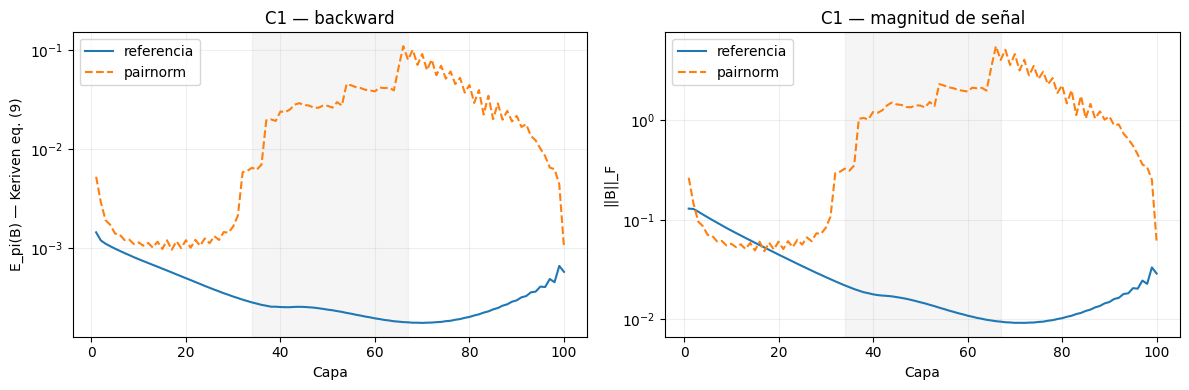

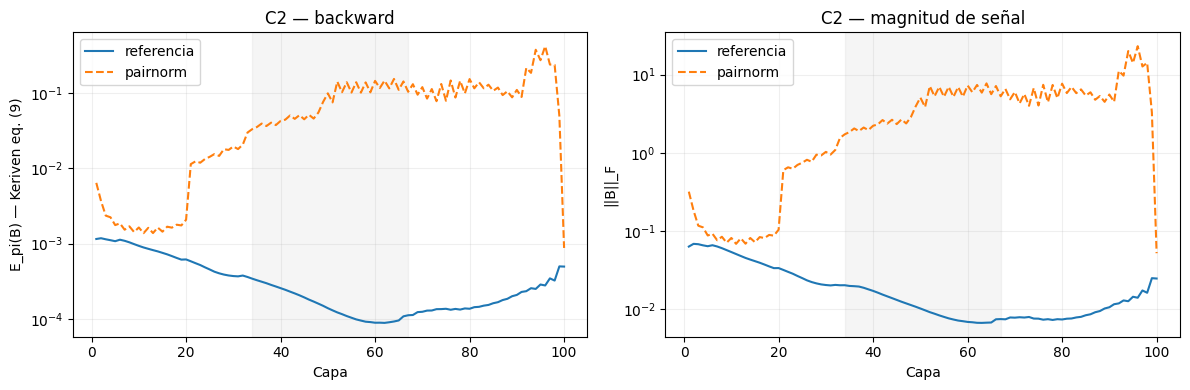

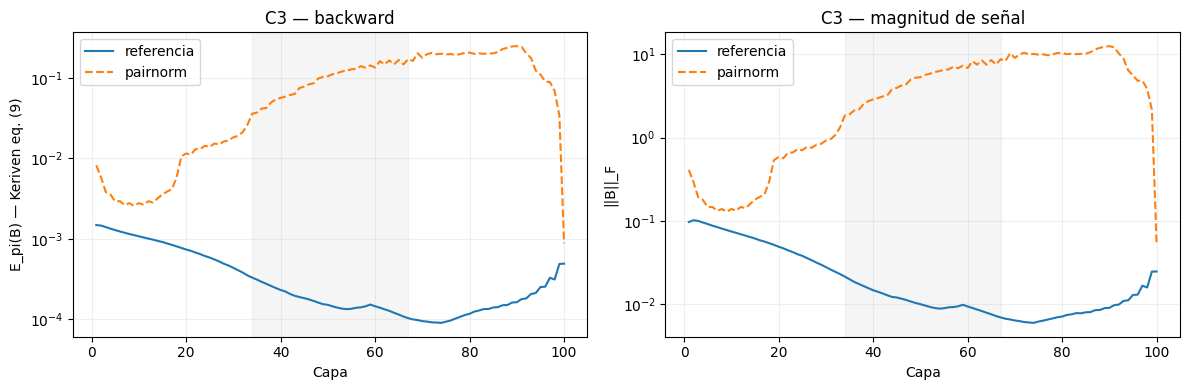

In [20]:
if not profiles_df.empty:
    selected = profiles_df[profiles_df['epoch']==EPOCHS].copy()
    if selected.empty:
        print('No hay perfiles finales a 1000 épocas todavía.')
    else:
        middle = (selected[selected.middle_layer]
                  .groupby(['config_id','seed','condition'],as_index=False)
                  .agg(mean_Epi_middle=('Epi_B','mean'),mean_norm_B_middle=('norm_B','mean')))
        middle.to_csv(OUTPUT_DIR/'resumen_backward_central.csv',index=False)
        display(middle.head(20))
        for cid in sorted(selected.config_id.unique()):
            sub=selected[selected.config_id==cid]
            fig,ax=plt.subplots(1,2,figsize=(12,4))
            for cond,style in [('referencia','-'),('pairnorm','--')]:
                df=sub[sub.condition==cond]
                agg=df.groupby('layer')[['Epi_B','norm_B']].median()
                ax[0].plot(agg.index,agg.Epi_B,style,label=cond)
                ax[1].plot(agg.index,agg.norm_B,style,label=cond)
            ax[0].set(ylabel='E_pi(B) — Keriven eq. (9)',xlabel='Capa',title=f'{cid} — backward')
            ax[1].set(ylabel='||B||_F',xlabel='Capa',title=f'{cid} — magnitud de señal')
            for a in ax:
                a.set_yscale('symlog',linthresh=1e-12); a.axvspan(34,67,alpha=.08,color='grey'); a.grid(alpha=.2); a.legend()
            fig.tight_layout();fig.savefig(OUTPUT_DIR/f'{cid}_backward.png',dpi=170);plt.show()

## 11. H1b: pérdida durante el entrenamiento

Se representa la mediana de la pérdida por época entre las cuatro semillas de cada condición. El eje vertical usa escala `symlog` para permitir visualizar valores muy distintos. También se presenta la pérdida final de cada condición en C1, C2 y C3.


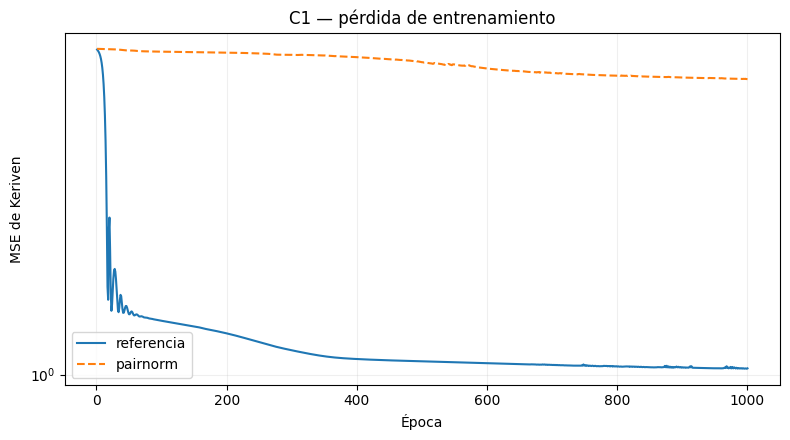

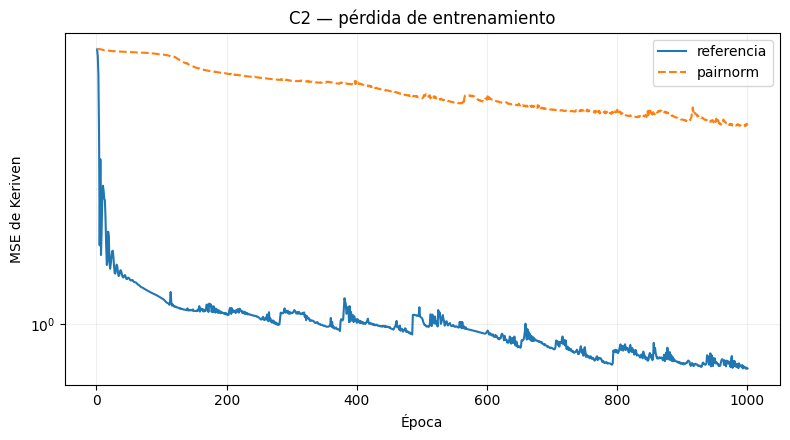

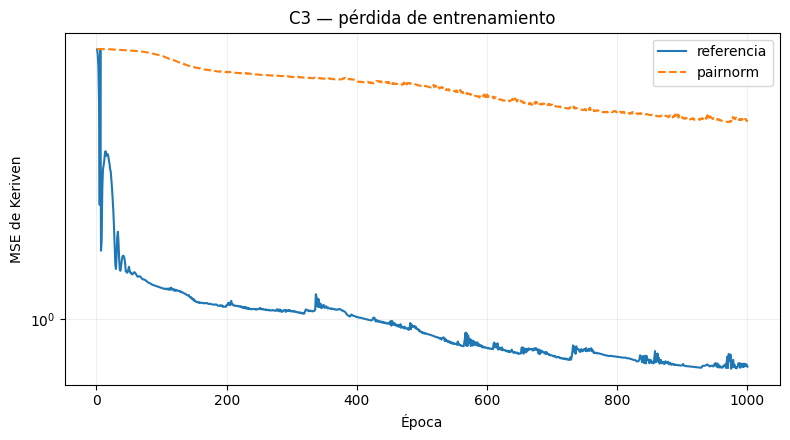

count      mean       std    median
config_id condition                                      
C1        pairnorm        4  4.537926  0.056022  4.530189
          referencia      4  1.035295  0.008072  1.031381
C2        pairnorm        4  3.365694  0.110375  3.382967
          referencia      4  0.787547  0.102262  0.763095
C3        pairnorm        4  3.374291  0.114212  3.429548
          referencia      4  0.748690  0.075474  0.752247

In [21]:
if not hist_df.empty:
    for cid in sorted(hist_df.config_id.unique()):
        sub=hist_df[hist_df.config_id==cid]
        fig, ax=plt.subplots(figsize=(8,4.5))
        for cond,style in [('referencia','-'),('pairnorm','--')]:
            ss=sub[sub.condition==cond]
            series=ss.groupby('epoch')['loss'].median()
            ax.plot(series.index,series.values,style,label=cond)
        ax.set(xlabel='Época',ylabel='MSE de Keriven',title=f'{cid} — pérdida de entrenamiento')
        ax.set_yscale('symlog',linthresh=1e-7);ax.grid(alpha=.2);ax.legend()
        fig.tight_layout();fig.savefig(OUTPUT_DIR/f'{cid}_perdida.png',dpi=170);plt.show()

if not runs_df.empty:
    done=runs_df[runs_df.status=='ok']
    display(done.groupby(['config_id','condition'])['final_loss'].agg(['count','mean','std','median']))

## 12. Exportación de resultados

Se guardan los CSV de pérdida, los perfiles por capa, las comparaciones por semilla y las gráficas de las tres configuraciones. El archivo ZIP reúne los datos y figuras; los checkpoints permanecen en la carpeta de entrenamiento.

In [22]:
import zipfile
bundle=OUTPUT_DIR.parent/'Keriven_PairNorm_Resultados.zip'
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as zf:
    for f in OUTPUT_DIR.rglob('*'):
        if f.is_file() and 'checkpoints' not in f.parts:  # checkpoints pueden ser muy grandes
            zf.write(f, arcname=str(f.relative_to(OUTPUT_DIR)))
print('Carpeta:',OUTPUT_DIR)
print('Archivo ZIP:',bundle)
try:
    from google.colab import files
    files.download(str(bundle))
except ImportError:
    print('Fuera de Colab: el ZIP está guardado en la ruta anterior.')

Carpeta: /content/drive/MyDrive/Keriven_PairNorm
Archivo ZIP: /content/drive/MyDrive/Keriven_PairNorm_Resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Referencias

1. **Keriven, N. (2026).** [*Backward Oversmoothing: why is it hard to train deep Graph Neural Networks?*](https://proceedings.mlr.press/v306/keriven26a.html). ICML, PMLR 306. Ecuaciones (1), (4)–(9), teoremas 3.4 y 4.2; apéndice B.
2. **Zhao, L. y Akoglu, L. (2020).** [*PairNorm: Tackling Oversmoothing in GNNs*](https://openreview.net/forum?id=rkecl1rtwB). ICLR 2020.
3. **Yang, Z., Cohen, W. W. y Salakhutdinov, R. (2016).** [*Revisiting Semi-Supervised Learning with Graph Embeddings*](https://proceedings.mlr.press/v48/yanga16.html). ICML, PMLR 48, pp. 40–48. Referencia del conjunto Cora/Planetoid.
